# Nutrition QAOA — start here

Upload **two files** to the same Jupyter folder: `start_here.ipynb` and `nutrition_qaoa_extended.tar.gz`. Open this notebook and choose **Run All**. It unpacks the complete project (including `data/foods.csv`), installs packages, checks the model, runs the exhaustive classical baseline and the 16-qubit QAOA experiment, then displays the results. No API key or separate data download is required. First choose a Python 3.11 or 3.12 **Jupyter kernel** (Kernel → Change Kernel); having Python 3.11 installed elsewhere on the server does not change this notebook's kernel. Request at least 4 vCPUs and 16 GB RAM. The first run needs internet access to install packages. GPU selection is automatic; if no usable GPU is allocated, the notebook reports why and continues on CPU.

Each Run All creates a new folder under `outputs/runs/` with a live `notebook.log`, `progress.jsonl`, and `status.json`. The page also prints a heartbeat every 30 seconds, so a long silent step is visible. If a run stops, inspect those files in Jupyter's file browser; the last event and phase show where it stopped.

The food and nutrition settings are illustrative, not a clinical meal plan. See `README.md` for sources and modelling limitations.

In [ ]:


from pathlib import Path
from pathlib import PurePosixPath
import hashlib
import json
import os
import platform
import shutil
import subprocess
import sys
import threading
import time
import tarfile
from datetime import datetime, timezone

notebook_dir = Path.cwd().resolve()
archive_name = 'nutrition_qaoa_extended.tar.gz'
archive_path = next((p / archive_name for p in (notebook_dir, notebook_dir.parent) if (p / archive_name).is_file()), None)
required_bundle_files = {'requirements.txt', 'config.json', 'model.py', 'progress.py', 'gpu_probe.py', 'run_experiments.py', 'test_model.py', 'test_experiment_design.py', 'test_progress.py', 'test_gpu_probe.py', 'data/foods.csv', 'data/food_manifest.csv'}
bundle_hash = None
if archive_path is not None:
    with archive_path.open('rb') as handle:
        bundle_hash = hashlib.file_digest(handle, 'sha256').hexdigest()
    project_dir = notebook_dir / ('nutrition_qaoa_extended_' + bundle_hash[:12])
    marker = project_dir / '.bundle_sha256'
    reusable = marker.is_file() and marker.read_text(encoding='utf-8').strip() == bundle_hash
    reusable = reusable and all((project_dir / name).is_file() for name in required_bundle_files)
    if not reusable:
        if project_dir.exists():
            project_dir = notebook_dir / ('nutrition_qaoa_extended_' + bundle_hash[:12] + '_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
        with tarfile.open(archive_path, 'r:gz') as bundle:
            members = bundle.getmembers()
            names = {entry.name for entry in members if entry.isfile()}
            missing = sorted(required_bundle_files - names)
            if missing:
                raise FileNotFoundError(f'Archive is incomplete; missing {missing}. Upload the complete nutrition_qaoa_extended.tar.gz.')
            if len(names) != len([entry for entry in members if entry.isfile()]):
                raise ValueError('Archive has duplicate file names.')
            for entry in members:
                parts = PurePosixPath(entry.name).parts
                if not parts or PurePosixPath(entry.name).is_absolute() or '..' in parts or any(':' in part or '\\' in part for part in parts) or not (entry.isfile() or entry.isdir()):
                    raise ValueError(f'Unsafe archive entry: {entry.name}')
            project_dir.mkdir(parents=True, exist_ok=False)
            for entry in members:
                target = project_dir.joinpath(*PurePosixPath(entry.name).parts)
                if entry.isdir():
                    target.mkdir(parents=True, exist_ok=True)
                else:
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with bundle.extractfile(entry) as source, target.open('xb') as destination:
                        shutil.copyfileobj(source, destination)
        (project_dir / '.bundle_sha256').write_text(bundle_hash, encoding='utf-8')
        print('Extracted archive:', archive_path, '→', project_dir)
    else:
        print('Using previously verified archive extraction:', project_dir)
else:
    project_dir = notebook_dir
    if not (project_dir / 'run_experiments.py').is_file():
        project_dir = notebook_dir / 'nutrition_qaoa_extended'
    missing = sorted(name for name in required_bundle_files if not (project_dir / name).is_file())
    if missing:
        raise FileNotFoundError(f'Project files missing: {missing}. Upload start_here.ipynb and nutrition_qaoa_extended.tar.gz to the same Jupyter folder, then Run All.')
print('Project:', project_dir)
print('Python:', sys.version.split()[0])
print('Kernel executable:', sys.executable)
if sys.version_info[:2] not in ((3, 11), (3, 12)):
    raise RuntimeError(
        f'This notebook is running in Python {sys.version.split()[0]} at {sys.executable}. '
        'In Jupyter, choose Kernel → Change Kernel → Python 3.11 or 3.12, then Restart & Run All. '
        'Installing another Python on the server does not switch the notebook kernel.'
    )

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
output_dir = project_dir / 'outputs' / 'runs' / run_id
output_dir.mkdir(parents=True, exist_ok=False)
session_log = output_dir / 'notebook.log'
log_lock = threading.Lock()

def show_and_save(message):
    with log_lock:
        with session_log.open('a', encoding='utf-8') as handle:
            handle.write(message)
    print(message, end='', flush=True)

def note(message):
    timestamp = datetime.now(timezone.utc).isoformat(timespec='seconds')
    show_and_save(f'[{timestamp}] {message}\n')

def run_logged(label, command, cwd=None):
    note(f'START {label}: {command}')
    started = time.monotonic()
    last_output = [started]
    try:
        process = subprocess.Popen(
            command, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, errors='replace', bufsize=1,
        )
    except OSError as error:
        note(f'LAUNCH FAILED {label}: {type(error).__name__}: {error}')
        raise
    stop_heartbeat = threading.Event()
    def heartbeat():
        while not stop_heartbeat.wait(30):
            note(
                f'HEARTBEAT {label}: pid={process.pid}, '
                f'elapsed={time.monotonic() - started:.0f}s, '
                f'no child output for {time.monotonic() - last_output[0]:.0f}s'
            )
    monitor = threading.Thread(target=heartbeat, daemon=True)
    monitor.start()
    try:
        for line in process.stdout:
            show_and_save(line)
            last_output[0] = time.monotonic()
        exit_code = process.wait()
    except KeyboardInterrupt:
        note(f'INTERRUPTED {label}; terminating child process {process.pid}')
        process.terminate()
        try:
            process.wait(timeout=10)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        raise
    finally:
        stop_heartbeat.set()
        monitor.join(timeout=1)
        if process.stdout is not None:
            process.stdout.close()
    note(f'END {label}: exit_code={exit_code}, elapsed={time.monotonic() - started:.1f}s')
    if exit_code != 0:
        note(f'FAILED {label}: inspect {session_log}')
        raise RuntimeError(f'{label} failed (exit {exit_code}); inspect {session_log} and {output_dir / "status.json"}')

environment = {
    'python': sys.version, 'executable': sys.executable,
    'platform': platform.platform(), 'cpu_count_visible': os.cpu_count(),
    'project_dir': str(project_dir), 'run_id': run_id,
    'archive_path': str(archive_path) if archive_path else None, 'bundle_sha256': bundle_hash,
}
(output_dir / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
note(f'Diagnostics folder: {output_dir}')

Extracted archive: /home/REDACTED_USER/qutam/nutrition_qaoa_extended.tar.gz → /home/REDACTED_USER/qutam/nutrition_qaoa_extended_ebc7c3a2268f
Project: /home/REDACTED_USER/qutam/nutrition_qaoa_extended_ebc7c3a2268f
Python: 3.11.9
Kernel executable: /home/REDACTED_USER/py311-kernel/bin/python
[2026-10-14T10:31:17+00:00] Diagnostics folder: /home/REDACTED_USER/qutam/nutrition_qaoa_extended_ebc7c3a2268f/outputs/runs/20261014T103117_956650Z


## Install required packages

This installs into the notebook's current Python environment. The experiment runs in a fresh Python subprocess, so no kernel restart is needed.

In [2]:
run_logged(
    'install dependencies',
    [sys.executable, '-u', '-m', 'pip', 'install', '-r', str(project_dir / 'requirements.txt')],
    cwd=project_dir,
)

[2026-10-14T10:31:17+00:00] START install dependencies: ['/home/REDACTED_USER/py311-kernel/bin/python', '-u', '-m', 'pip', 'install', '-r', '/home/REDACTED_USER/qutam/nutrition_qaoa_extended_ebc7c3a2268f/requirements.txt']
[2026-10-14T10:31:18+00:00] END install dependencies: exit_code=0, elapsed=0.5s


## Optional USDA source-record download

The checked-in dataset is all the program needs. If you want to audit the food values against USDA FoodData Central, obtain an API key from https://fdc.nal.usda.gov/api-guide/, set `FDC_API_KEY` in the Jupyter server environment, and set `DOWNLOAD_USDA = True` below. The downloaded candidate data will be saved separately; it will **not** replace `data/foods.csv`. Do not paste or save your key in this notebook.

In [3]:
DOWNLOAD_USDA = False
if DOWNLOAD_USDA:
    if not os.environ.get('FDC_API_KEY'):
        raise RuntimeError('Set FDC_API_KEY in the Jupyter server environment first.')
    run_logged('download optional USDA records', [sys.executable, '-u', str(project_dir / 'fetch_usda.py')], cwd=project_dir)
else:
    print('Using the included data/foods.csv; no data download is needed.')

Using the included data/foods.csv; no data download is needed.


## Experiment settings

The default comparison is **p=1,2,3,4 × 3 independent QAOA seeds × 3 random starts × 2 optimizers = 72 optimization runs**. All runs have the same 400-objective-evaluation cap, and each optimized distribution is sampled at 1,024, 4,096 and 16,384 shots. On the CPU this may take roughly 1–3 hours; request a 4-hour Jupyter job, and use the progress files to check actual speed. `SEED` controls only the separate nutrition-policy sensitivity analysis; `QAOA_SEEDS` control independent angle initialization and measurement streams. `RUN_QAOA = False` runs only the model checks and classical baseline. `DEVICE = 'AUTO'` uses a CUDA device visible to this Jupyter job or CPU otherwise. Set `DEVICE = 'GPU'` to require a GPU and fail clearly if unavailable. Slurm `sbatch --test-only` checks estimate starts but do not allocate a GPU to this running notebook.

In [4]:
RUN_QAOA = True
DEPTHS = [1, 2, 3, 4]
QAOA_SEEDS = [1, 7, 21]
RESTARTS = 3
OPTIMIZERS = ['COBYLA', 'Nelder-Mead']
MAX_EVALUATIONS = 400  # Same objective-evaluation cap for each depth and optimizer
SHOTS = 4096
SHOT_COUNTS = [1024, 4096, 16384]
SENSITIVITY_RUNS = 100
SEED = 7
DEVICE = 'AUTO'  # AUTO, CPU, or GPU
CUDA_MAJOR = None  # Driver-reported maximum CUDA version; override only if probe omits it
CHECK_GPU_QUEUE = True
SLURM_ACCOUNT = os.environ.get('SLURM_JOB_ACCOUNT') or os.environ.get('SBATCH_ACCOUNT')
QUEUE_HOURS = 4
QUEUE_CONSTRAINTS = ['a100-80gb', 'a100', 'a40', 'l40s', 'v100']

## Select and verify the simulator

GPU simulation requires a CUDA device available **inside this Jupyter job**, x86-64 Linux, and a working NVIDIA driver. The probe checks the CUDA driver directly, so a missing `nvidia-smi` command alone does not force CPU mode. Full driver, allocation, `nvidia-smi`, and CUDA API details are printed below and saved as `gpu_probe.json`. `AUTO` continues on CPU with an explicit reason when no CUDA device is available; `GPU` stops instead. The currently pinned Aer 0.17 GPU wheel is published on PyPI as `qiskit-aer-gpu-cu11`; a GPU smoke test verifies it before the experiment. The classical baseline and optimizer control code still run on CPU.

In [5]:
sys.path.insert(0, str(project_dir))
from gpu_probe import probe_gpu

requested_device = DEVICE.upper()
if requested_device not in {'AUTO', 'CPU', 'GPU'}:
    raise ValueError('DEVICE must be AUTO, CPU, or GPU.')
gpu_details = probe_gpu()
gpu_probe_path = output_dir / 'gpu_probe.json'
gpu_probe_path.write_text(json.dumps(gpu_details, indent=2), encoding='utf-8')
print('GPU probe details:', json.dumps(gpu_details, indent=2), flush=True)
gpu_visible = gpu_details['visible']
detected_cuda_major = (gpu_details['cuda'] or {}).get('driver_cuda_major')
note(f'GPU probe: visible={gpu_visible}, detected CUDA major={detected_cuda_major}, reason={gpu_details["reason"]}; details={gpu_probe_path}')
if CHECK_GPU_QUEUE and not gpu_visible:
    queue_results = []
    sbatch_path = shutil.which('sbatch')
    if not sbatch_path or not SLURM_ACCOUNT:
        note('Slurm queue estimate skipped: sbatch unavailable or SLURM_ACCOUNT unset.')
    else:
        for constraint in QUEUE_CONSTRAINTS:
            command = [sbatch_path, '--test-only', '--account=' + SLURM_ACCOUNT, '--partition=gpu', '--ntasks=1', '--gpus-per-task=1', '--constraint=' + constraint, '--time=' + str(QUEUE_HOURS) + ':00:00', '--wrap=hostname']
            try:
                result = subprocess.run(command, capture_output=True, text=True, errors='replace', timeout=10, check=False)
                record = {'constraint': constraint, 'exit_code': result.returncode, 'stdout': result.stdout, 'stderr': result.stderr}
            except (OSError, subprocess.TimeoutExpired) as error:
                record = {'constraint': constraint, 'error': f'{type(error).__name__}: {error}'}
            queue_results.append(record)
            note(f'Slurm estimate {constraint}: {record}')
        (output_dir / 'gpu_queue_estimates.json').write_text(json.dumps(queue_results, indent=2), encoding='utf-8')
effective_device = 'GPU' if (requested_device == 'AUTO' and gpu_visible) else requested_device
if effective_device == 'AUTO':
    effective_device = 'CPU'
requested_settings = {
    'run_qaoa': RUN_QAOA, 'depths': DEPTHS, 'qaoa_seeds': QAOA_SEEDS, 'restarts': RESTARTS,
    'optimizers': OPTIMIZERS, 'max_evaluations': MAX_EVALUATIONS,
    'shots': SHOTS, 'shot_counts': SHOT_COUNTS, 'sensitivity_runs': SENSITIVITY_RUNS, 'seed': SEED,
    'requested_device': DEVICE, 'effective_device': effective_device,
    'cuda_major': CUDA_MAJOR, 'detected_cuda_major': detected_cuda_major,
    'check_gpu_queue': CHECK_GPU_QUEUE, 'slurm_account': SLURM_ACCOUNT,
    'queue_hours': QUEUE_HOURS, 'queue_constraints': QUEUE_CONSTRAINTS,
}
gpu_fallback_error = None
if effective_device == 'GPU':
    if not gpu_visible:
        raise RuntimeError(f'GPU requested but unavailable: {gpu_details["reason"]}. See {gpu_probe_path}. Check that the Jupyter job itself was allocated a GPU.')
    try:
        cuda_major = CUDA_MAJOR if CUDA_MAJOR is not None else detected_cuda_major
        if cuda_major is not None and cuda_major < 11:
            raise RuntimeError(f'CUDA driver supports only version {cuda_major}; the Aer GPU package requires CUDA 11 or newer.')
        gpu_package = 'qiskit-aer-gpu-cu11>=0.17,<0.18'
        note(f'Installing {gpu_package} for driver-reported CUDA {cuda_major}; the smoke test verifies actual GPU execution')
        run_logged('install GPU simulator', [sys.executable, '-u', '-m', 'pip', 'install', gpu_package], cwd=project_dir)
        smoke_test = (
            'from qiskit import QuantumCircuit; '
            'from qiskit_aer import AerSimulator; '
            'q = QuantumCircuit(1); q.h(0); q.save_statevector(); '
            'sim = AerSimulator(method="statevector", device="GPU", target_gpus=[0]); '
            'result = sim.run(q).result(); assert result.success; '
            'print(sim.available_devices())'
        )
        run_logged('GPU smoke test', [sys.executable, '-u', '-c', smoke_test], cwd=project_dir)
        note('GPU smoke test passed')
    except RuntimeError as error:
        if requested_device == 'GPU':
            raise
        gpu_fallback_error = str(error)
        note(f'GPU setup failed in AUTO mode: {error}; verifying CPU fallback')
        cpu_smoke = 'from qiskit_aer import AerSimulator; from qiskit import QuantumCircuit; q=QuantumCircuit(1); q.h(0); q.save_statevector(); r=AerSimulator(method="statevector", device="CPU").run(q).result(); assert r.success'
        run_logged('CPU fallback smoke test', [sys.executable, '-u', '-c', cpu_smoke], cwd=project_dir)
        effective_device = 'CPU'
else:
    note('Using CPU simulation. ' + (gpu_details['reason'] if requested_device == 'AUTO' else 'CPU was explicitly requested.') + ' No GPU package is required.')
requested_settings['effective_device'] = effective_device
requested_settings['gpu_fallback_error'] = gpu_fallback_error
(output_dir / 'requested_settings.json').write_text(json.dumps(requested_settings, indent=2), encoding='utf-8')
note(f'Selected QAOA simulator: {effective_device}')
from importlib import metadata
package_names = [
    'numpy', 'scipy', 'matplotlib', 'qiskit', 'qiskit-aer',
    'qiskit-aer-gpu', 'qiskit-aer-gpu-cu11', 'qiskit-optimization', 'requests',
]
package_versions = {}
for name in package_names:
    try:
        package_versions[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        package_versions[name] = None
(output_dir / 'packages.json').write_text(json.dumps(package_versions, indent=2), encoding='utf-8')

GPU probe details: {
  "hostname": "REDACTED_CLUSTER_HOST",
  "system": "Linux",
  "machine": "x86_64",
  "linux_x64": true,
  "environment": {
    "CUDA_VISIBLE_DEVICES": null,
    "NVIDIA_VISIBLE_DEVICES": null,
    "SLURM_JOB_GPUS": null,
    "SLURM_GPUS_ON_NODE": null,
    "PBS_GPUFILE": null
  },
  "nvidia_smi_path": null,
  "nvidia_smi_exit_code": null,
  "nvidia_smi_stdout": "",
  "nvidia_smi_stderr": "",
  "nvidia_smi_error": null,
  "cuda": {
    "library": "libcuda.so.1",
    "load_error": "libcuda.so.1: cannot open shared object file: No such file or directory",
    "init_result": null,
    "device_count_result": null,
    "device_count": 0,
    "driver_version_result": null,
    "driver_version_raw": null,
    "driver_cuda_major": null
  },
  "visible": false,
  "reason": "CUDA driver library libcuda.so.1 is unavailable in this kernel"
}
[2026-10-14T10:31:18+00:00] GPU probe: visible=False, detected CUDA major=None, reason=CUDA driver library libcuda.so.1 is unavailable in 

231

## Run tests and experiment

The exhaustive baseline searches all 65,536 menus, without a fixed total-serving constraint. Progress includes depth, optimizer, independent seed, restart and evaluation number; results are checkpointed after every optimization run. The full p=1–4 comparison may take hours on CPU. `status.json` shows the latest phase; `progress.jsonl` preserves the full event history even if the process stops.

In [6]:
run_logged(
    'model and diagnostics tests',
    [sys.executable, '-u', '-m', 'unittest', 'discover', '-s', str(project_dir), '-p', 'test_*.py', '-v'],
    cwd=project_dir,
)
command = [
    sys.executable, '-u', str(project_dir / 'run_experiments.py'),
    '--output', str(output_dir),
    '--depths', *map(str, DEPTHS),
    '--restarts', str(RESTARTS),
    '--optimizers', *OPTIMIZERS,
    '--max-evaluations', str(MAX_EVALUATIONS),
    '--shots', str(SHOTS),
    '--shot-counts', *map(str, SHOT_COUNTS),
    '--sensitivity-runs', str(SENSITIVITY_RUNS),
    '--seed', str(SEED),
    '--qaoa-seeds', *map(str, QAOA_SEEDS),
    '--device', effective_device,
]
if not RUN_QAOA:
    command.append('--analysis-only')
run_logged('nutrition QAOA experiment', command, cwd=project_dir)

[2026-10-14T10:31:18+00:00] START model and diagnostics tests: ['/home/REDACTED_USER/py311-kernel/bin/python', '-u', '-m', 'unittest', 'discover', '-s', '/home/REDACTED_USER/qutam/nutrition_qaoa_extended_ebc7c3a2268f', '-p', 'test_*.py', '-v']
test_notebook_extracts_archive_before_looking_at_partial_upload (test_bundle_bootstrap.BundleBootstrapTests.test_notebook_extracts_archive_before_looking_at_partial_upload) ... Extracted archive: /tmp/SLURM_13092117/tmp672mdajy/nutrition_qaoa_extended.tar.gz → /tmp/SLURM_13092117/tmp672mdajy/nutrition_qaoa_extended_6f691a9b1acc
Project: /tmp/SLURM_13092117/tmp672mdajy/nutrition_qaoa_extended_6f691a9b1acc
Python: 3.11.9
Kernel executable: /home/REDACTED_USER/py311-kernel/bin/python
[2026-10-14T10:31:19+00:00] Diagnostics folder: /tmp/SLURM_13092117/tmp672mdajy/nutrition_qaoa_extended_6f691a9b1acc/outputs/runs/20261014T103119_122220Z
ok
test_default_design_includes_four_depths_and_independent_seeds (test_experiment_design.ExperimentDesignTests.test

## Inspect results

Each run writes results and diagnostics to its own `outputs/runs/<run_id>/` folder, downloadable through Jupyter's file browser. The classical optimum is evaluated with the true cost function; QAOA optimizes an approximate QUBO, whose mismatch is reported separately. If a run fails before this cell, browse the printed diagnostics folder and inspect `notebook.log`, `status.json`, and the end of `progress.jsonl`.

Exact best menu: eggsx2, oatmealx3, chickenx2, ricex1, vegetablesx3, bananax3, peanut_butterx1, pizzax2
Portions: 17
Distinct foods: 8
True cost: -0.02
Nutrients: {'kcal': 2600.0, 'protein_g': 156.2, 'carbs_g': 281.3, 'fat_g': 99.5, 'potassium_mg': 3810.0, 'sodium_mg': 2295.0}
QUBO-best true rank: 28
True-best QUBO rank: 1008
Near-optimum QUBO mean absolute error: 0.07852903484527368
Compare alternative QUBO fits in surrogate_fit_comparison.csv; the uniform fit remains the QAOA objective.


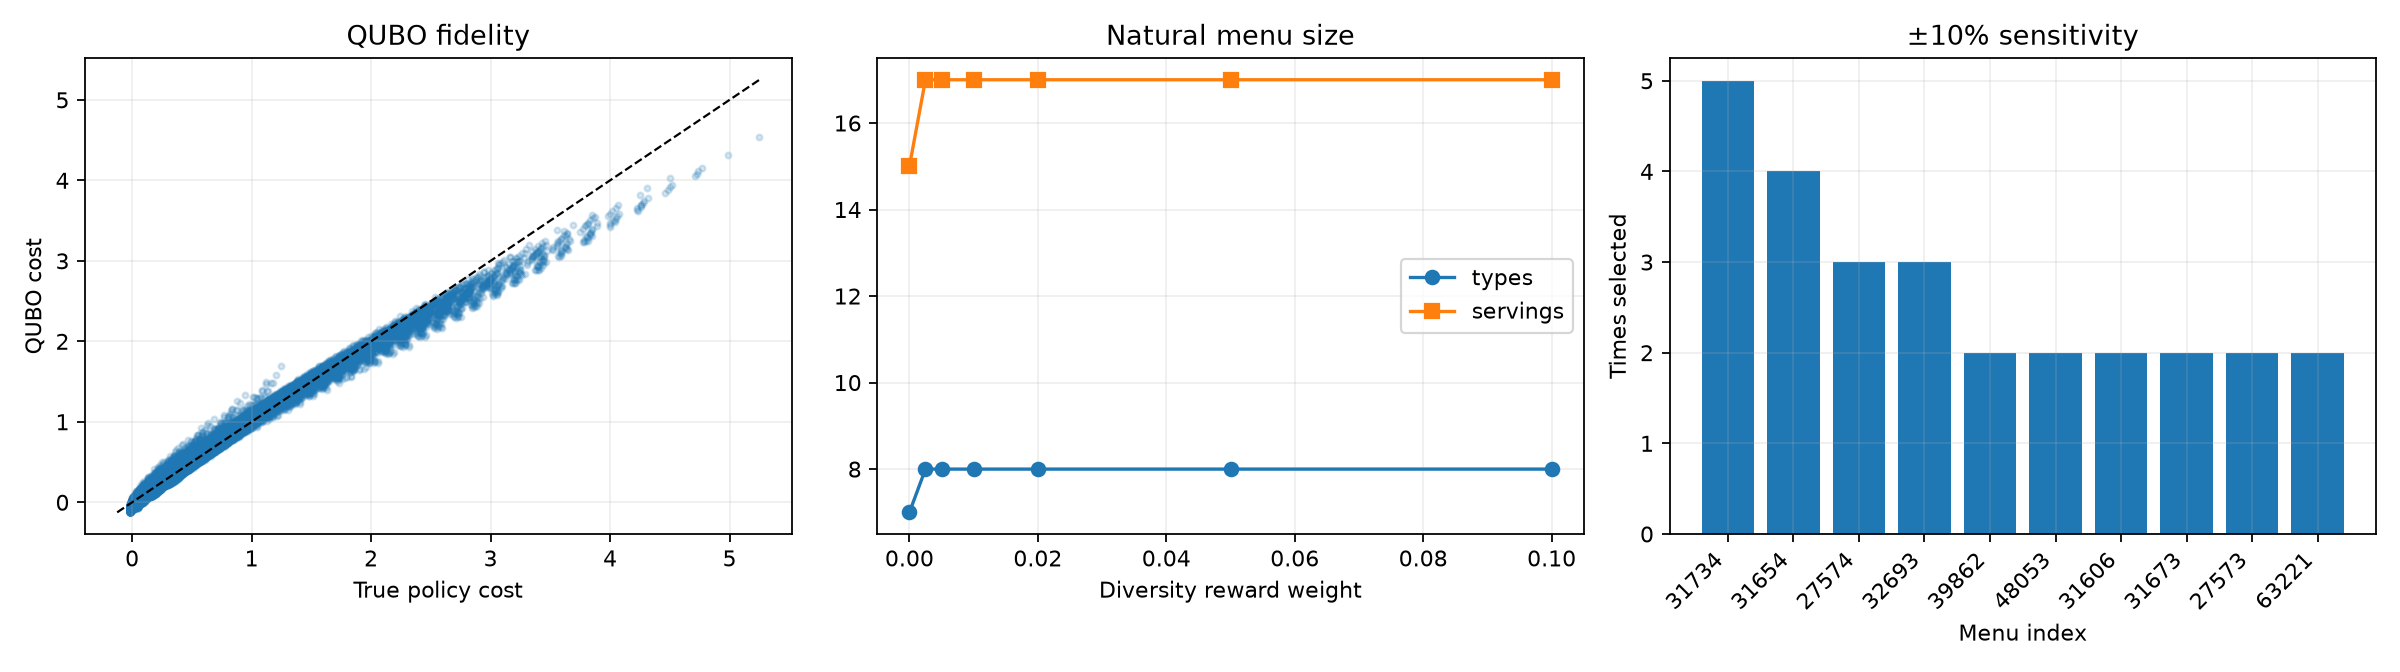

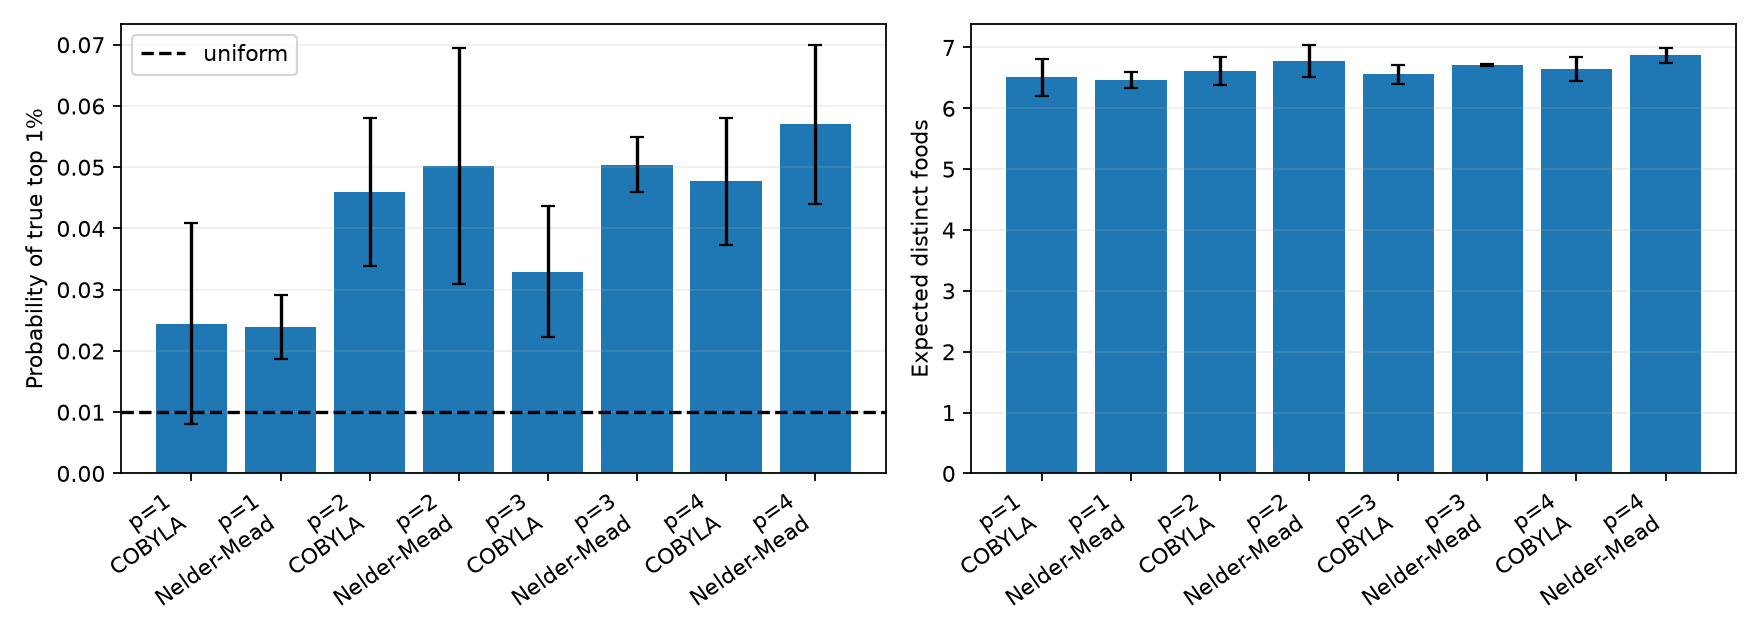

QAOA summary: mean ± SD across independent seed means (lower true cost is better)
p=1 COBYLA: seeds=3, runs=9, true top 1%=2.448% ± 1.647%, expected true cost=0.26964 ± 0.16471
p=1 Nelder-Mead: seeds=3, runs=9, true top 1%=2.393% ± 0.524%, expected true cost=0.27131 ± 0.06330
p=2 COBYLA: seeds=3, runs=9, true top 1%=4.592% ± 1.207%, expected true cost=0.26576 ± 0.08202
p=2 Nelder-Mead: seeds=3, runs=9, true top 1%=5.020% ± 1.934%, expected true cost=0.19936 ± 0.09650
p=3 COBYLA: seeds=3, runs=9, true top 1%=3.297% ± 1.072%, expected true cost=0.33454 ± 0.08102
p=3 Nelder-Mead: seeds=3, runs=9, true top 1%=5.041% ± 0.452%, expected true cost=0.24779 ± 0.03716
p=4 COBYLA: seeds=3, runs=9, true top 1%=4.773% ± 1.038%, expected true cost=0.28232 ± 0.08482
p=4 Nelder-Mead: seeds=3, runs=9, true top 1%=5.698% ± 1.291%, expected true cost=0.22351 ± 0.07243
See qaoa_shot_sweep_summary.csv for how 1,024/4,096/16,384 shots affect the best observed rank.
Download files from the Jupyter file brows

In [7]:
from IPython.display import Image, display

baseline = json.loads((output_dir / 'baseline_summary.json').read_text(encoding='utf-8'))
print('Exact best menu:', baseline['true_best']['menu'])
print('Portions:', baseline['true_best']['total_servings'])
print('Distinct foods:', baseline['true_best']['distinct_foods'])
print('True cost:', baseline['true_best']['policy_cost'])
print('Nutrients:', baseline['true_best']['totals'])
print('QUBO-best true rank:', baseline['surrogate_validation']['surrogate_best_true_rank'])
print('True-best QUBO rank:', baseline['surrogate_validation']['true_best_surrogate_rank'])
print('Near-optimum QUBO mean absolute error:', baseline['surrogate_validation']['near_optimum_mae'])
print('Compare alternative QUBO fits in surrogate_fit_comparison.csv; the uniform fit remains the QAOA objective.')
display(Image(filename=str(output_dir / 'baseline_analysis.png')))
qaoa_plot = output_dir / 'qaoa_summary.png'
if qaoa_plot.is_file() and RUN_QAOA:
    display(Image(filename=str(qaoa_plot)))
if RUN_QAOA and (output_dir / 'qaoa_summary.csv').is_file():
    import csv
    print('QAOA summary: mean ± SD across independent seed means (lower true cost is better)')
    with (output_dir / 'qaoa_summary.csv').open(newline='', encoding='utf-8') as handle:
        for row in csv.DictReader(handle):
            print(f"p={row['depth']} {row['optimizer']}: seeds={row['seeds']}, runs={row['runs']}, true top 1%={float(row['p_true_top_1pct_mean']):.3%} ± {float(row['p_true_top_1pct_std']):.3%}, expected true cost={float(row['expected_true_policy_cost_mean']):.5f} ± {float(row['expected_true_policy_cost_std']):.5f}")
    print('See qaoa_shot_sweep_summary.csv for how 1,024/4,096/16,384 shots affect the best observed rank.')
print('Download files from the Jupyter file browser:', output_dir)
for result_file in sorted(output_dir.iterdir()):
    if result_file.is_file():
        print(' -', result_file.name)
status = json.loads((output_dir / 'status.json').read_text(encoding='utf-8'))
print('Final run status:', status['state'], '| phase:', status['phase'])

## If a run stopped: inspect the latest diagnostics

Run the next cell **by itself**, even after restarting the Jupyter kernel. It finds the newest run folder, displays the latest status and the last lines of both logs. `status.json` and `progress.jsonl` remain available for download and contain more detail. A recent heartbeat with no completed optimizer evaluation means the process was alive but waiting inside that step; no recent heartbeat may mean the process or node stopped.

In [8]:
from pathlib import Path
import json

diagnostic_project = Path.cwd().resolve()
if not (diagnostic_project / 'run_experiments.py').is_file():
    diagnostic_project = diagnostic_project / 'nutrition_qaoa_extended'
run_folders = [folder for folder in (diagnostic_project / 'outputs' / 'runs').glob('*') if folder.is_dir()]
if not run_folders:
    print('No saved run folders found.')
else:
    latest = max(run_folders, key=lambda folder: folder.stat().st_mtime)
    print('Latest run:', latest)
    status_file = latest / 'status.json'
    if status_file.is_file():
        print('Status:', json.dumps(json.loads(status_file.read_text(encoding='utf-8')), indent=2))
    else:
        print('No experiment status yet; inspect notebook.log for setup or installation errors.')
    for filename in ('notebook.log', 'progress.jsonl'):
        diagnostic_file = latest / filename
        print('\n---', filename, '(last 40 lines) ---')
        if diagnostic_file.is_file():
            for line in diagnostic_file.read_text(encoding='utf-8', errors='replace').splitlines()[-40:]:
                print(line)
        else:
            print('Not created yet')

No saved run folders found.
